# Parte 2 — Modelo do `klike_score`

Objetivo: prever o `klike_score` e entender o que mais pesa nele. As decisões estão explicadas no [README](../README.md).

Roteiro: 
· 1. Dados e validação 
· 2. Features 
· 3. Comparação de modelos 
· 4. Checagens
· 5. Avaliação no teste 
· 6. Importância das features

In [1]:
import sys
sys.path.append("..")

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, RepeatedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import make_pipeline

from src.modelo import GRADE_ALPHA, carregar_treino_teste
from src.preprocessamento import (CONTEXTO_BINARIAS, CONTEXTO_CATEGORICAS, CRIATIVO_BINARIAS, CRIATIVO_CATEGORICAS,
                                  CRIATIVO_NUMERICAS, LimpezaCampanhas, codificador, codificador_pos_veiculacao,
                                  codificador_pre_veiculacao)

PASTA_FIGURAS = Path("../figures")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COR = "#3a6da3"

## 1. Dados e validação

Mesma divisão da EDA (80/20, estratificada por plataforma). O teste só é usado uma vez, no fim.

Os modelos são comparados por validação cruzada no treino: 5 folds repetidos 3 vezes (15 avaliações por modelo), com os mesmos folds para todos os candidatos. Métrica principal, escolhida antes de ver os resultados: RMSE, o erro típico em pontos de score, que pesa mais os erros grandes. MAE e R² são reportados junto.

In [2]:
X_train, y_train, X_test, y_test = carregar_treino_teste()
CV = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)
METRICAS = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R²": "r2"}
print(f"treino: {X_train.shape}, teste: {X_test.shape}")

treino: (400, 25), teste: (100, 25)


## 2. Features

Toda a limpeza da EDA fica em `LimpezaCampanhas` (`src/preprocessamento.py`), o primeiro passo do pipeline. Assim ela é reajustada dentro de cada fold e aplicada igual a qualquer campanha nova.

Dois conjuntos de features:
- Pré-veiculação: só o que existe antes de a campanha ir ao ar, ou seja, atributos do criativo e contexto de mídia (plataforma, categoria, objetivo, público, retargeting).
- Pós-veiculação: o anterior mais as métricas de performance, como taxas: CTR, CPC, engajamento, retenção, conversão e ROAS.

Features novas, criadas a partir da EDA:

In [3]:
limpo = LimpezaCampanhas().fit_transform(X_train)
novas = ["watch_ratio", "conversion_rate", "log_ctr", "log_engagement_rate", "log_conversion_rate", "log_roas",
         "ctr_no_teto", "engagement_no_teto", "roas_nao_se_aplica"]
limpo[novas].describe().T[["count", "mean", "min", "max"]].round(3)

,count,mean,min,max
watch_ratio,351.0,0.546,0.033,1.000
conversion_rate,400.0,0.035,0.000,0.156
log_ctr,400.0,1.904,0.199,2.773
log_engagement_rate,373.0,1.148,0.095,2.398
log_conversion_rate,400.0,1.342,0.000,2.811
log_roas,357.0,1.080,0.000,3.347
ctr_no_teto,400.0,0.105,0.000,1.000
engagement_no_teto,400.0,0.018,0.000,1.000
roas_nao_se_aplica,400.0,0.108,0.000,1.000


- `watch_ratio` (tempo assistido / duração) e `conversion_rate` (conversões / cliques): taxas comparáveis entre campanhas de tamanhos diferentes (passo 6).
- Taxas em log: as relações com o score são multiplicativas (ex: dobrar o CTR pesa igual em qualquer nível).
- `ctr_no_teto` e `engagement_no_teto`: valor real desconhecido acima do teto (passo 4.4).
- `roas_nao_se_aplica`: receita não medida, em vez de ROAS zero (passo 4.3).
- Volumes (impressões, cliques, gasto) ficam de fora: medem o tamanho da campanha, não a qualidade do criativo, e quase não se relacionam com o score (passo 6).

In [4]:
for nome, cod in [("pré-veiculação", codificador_pre_veiculacao()), ("pós-veiculação", codificador_pos_veiculacao())]:
    colunas = cod.fit(limpo).get_feature_names_out()
    print(f"{nome}: {len(colunas)} colunas depois da codificação")

pré-veiculação: 33 colunas depois da codificação
pós-veiculação: 45 colunas depois da codificação


## 3. Comparação de modelos

Candidatos, todos no mesmo pipeline e nos mesmos folds:
- baseline: prevê sempre a média do treino;
- Ridge: regressão linear com regularização (hipótese do passo 8: efeitos aditivos);
- Random Forest e Gradient Boosting: capturam não linearidades e interações sem especificá-las.

Os hiperparâmetros de cada um são escolhidos por busca em grade com a mesma validação cruzada.

In [5]:
def candidatos(codificador_features):
    pipe = lambda modelo: make_pipeline(LimpezaCampanhas(), codificador_features(), modelo)
    return {
        "baseline (média)": (pipe(DummyRegressor()), {}),
        "Ridge": (pipe(Ridge()), GRADE_ALPHA),
        "Random Forest": (pipe(RandomForestRegressor(n_estimators=300, random_state=42)),
                          {"randomforestregressor__min_samples_leaf": [1, 3, 5, 10],
                           "randomforestregressor__max_features": [0.33, 0.6, 1.0]}),
        "Gradient Boosting": (pipe(HistGradientBoostingRegressor(max_iter=1000, random_state=42)),
                              {"histgradientboostingregressor__learning_rate": [0.01, 0.03, 0.1],
                               "histgradientboostingregressor__max_leaf_nodes": [2, 4, 8],
                               "histgradientboostingregressor__min_samples_leaf": [5, 10, 20, 40]}),
    }


CONJUNTOS = {"pré-veiculação": codificador_pre_veiculacao, "pós-veiculação": codificador_pos_veiculacao}
buscas = {}
for conjunto, cod in CONJUNTOS.items():
    for nome, (pipe, grade) in candidatos(cod).items():
        buscas[conjunto, nome] = GridSearchCV(pipe, grade, cv=CV, scoring=METRICAS, refit="RMSE", n_jobs=-1).fit(X_train, y_train)


def resumo(busca):
    i = busca.best_index_
    medias = {m: busca.cv_results_[f"mean_test_{m}"][i] * (1 if m == "R²" else -1) for m in METRICAS}
    return {**medias, "desvio do RMSE": busca.cv_results_["std_test_RMSE"][i]}


comparacao = pd.DataFrame({chave: resumo(busca) for chave, busca in buscas.items()}).T.rename_axis(["features", "modelo"])
comparacao.style.format("{:.3f}", subset=["R²"]).format("{:.2f}", subset=["RMSE", "MAE", "desvio do RMSE"])

In [6]:
with pd.option_context("display.max_colwidth", None):
    display(pd.Series({f"{c} / {m}": ", ".join(f"{k.split('__')[1]} = {float(v):.3g}" for k, v in b.best_params_.items())
                       for (c, m), b in buscas.items() if b.best_params_}, name="melhores hiperparâmetros").to_frame())

,melhores hiperparâmetros
pré-veiculação / Ridge,alpha = 3.16
pré-veiculação / Random Forest,"max_features = 0.6, min_samples_leaf = 5"
pré-veiculação / Gradient Boosting,"learning_rate = 0.03, max_leaf_nodes = 2, min_samples_leaf = 20"
pós-veiculação / Ridge,alpha = 3.16
pós-veiculação / Random Forest,"max_features = 0.6, min_samples_leaf = 3"
pós-veiculação / Gradient Boosting,"learning_rate = 0.03, max_leaf_nodes = 2, min_samples_leaf = 10"


- Ridge: `alpha` no meio da grade (0,01 a 1000) e igual nos dois conjuntos de features. É o valor fixado em `src/modelo.py`.
- Random Forest: os valores escolhidos ficam no interior da grade.
- Gradient Boosting: árvores com uma única divisão (`max_leaf_nodes = 2`, o menor valor possível). Uma soma de árvores assim é um modelo aditivo, sem interações: mesmo podendo usar interações, o boosting fica sem elas. A primeira grade parava em 4 folhas e a escolha caiu nesse limite, por isso a ampliei.

Comparação fold a fold entre o Ridge e os modelos de árvores (diferença de RMSE; positiva = Ridge melhor):

In [7]:
def rmse_por_fold(busca):
    return -np.array([busca.cv_results_[f"split{k}_test_RMSE"][busca.best_index_] for k in range(CV.get_n_splits())])


pd.DataFrame([
    {"features": conjunto, "comparação": f"{outro} − Ridge",
     "diferença média": (dif := rmse_por_fold(buscas[conjunto, outro]) - rmse_por_fold(buscas[conjunto, "Ridge"])).mean(),
     "desvio": dif.std(), "folds com Ridge melhor": f"{(dif > 0).sum()} de {len(dif)}"}
    for conjunto in CONJUNTOS for outro in ["Random Forest", "Gradient Boosting"]
]).round(2)

,features,comparação,diferença média,desvio,folds com Ridge melhor
0,pré-veiculação,Random Forest − Ridge,0.86,0.51,14 de 15
1,pré-veiculação,Gradient Boosting − Ridge,0.02,0.16,7 de 15
2,pós-veiculação,Random Forest − Ridge,1.87,0.63,15 de 15
3,pós-veiculação,Gradient Boosting − Ridge,-0.03,0.33,9 de 15


- O Ridge e o Gradient Boosting empatam nos dois conjuntos de features: as diferenças (0,02 ± 0,16 ponto no pré-veiculação e −0,03 ± 0,33 no pós-veiculação) são muito menores que a variação entre folds, e cada um ganha em cerca de metade dos folds.
- O Random Forest é pior que o Ridge em 14 de 15 folds no pré-veiculação e em 15 de 15 no pós-veiculação.
- O melhor Gradient Boosting é aditivo, e um modelo linear sem interações chega ao mesmo erro: os efeitos são aditivos (passos 6 e 7 da EDA). Com 400 campanhas, a flexibilidade extra das árvores não traz ganho.
- As métricas de performance reduzem o erro de 8,7 para 6,2 pontos (R² de 0,69 para 0,84).

Modelo escolhido: Ridge, nos dois conjuntos de features. No empate, fico com o modelo mais simples, cujos coeficientes dão o efeito de cada atributo em pontos de score.

## 4. Checagens

### 4.1 Interações com a plataforma

O passo 7 da EDA indicou que o efeito de cada atributo é o mesmo nas três plataformas. Se isso estiver certo, acrescentar interações atributo × plataforma ao Ridge não deve melhorar o erro.

In [8]:
class InteracoesPlataforma(BaseEstimator, TransformerMixin):
    """Cria colunas atributo × plataforma (TikTok e LinkedIn, com Meta como referência)."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        self.colunas_ = []
        for plataforma in ["TikTok", "LinkedIn"]:
            na_plataforma = (X["platform"] == plataforma).astype(float)
            for atributo in CRIATIVO_BINARIAS:
                X[f"{atributo} × {plataforma}"] = X[atributo].fillna(0) * na_plataforma
            for nivel in ["medium", "low"]:
                X[f"text_{nivel} × {plataforma}"] = (X["text_density"] == nivel) * na_plataforma
            self.colunas_ += [c for c in X.columns if c.endswith(f"× {plataforma}")]
        return X


interacoes = [f"{a} × {p}" for p in ["TikTok", "LinkedIn"] for a in CRIATIVO_BINARIAS + ["text_medium", "text_low"]]
com_interacoes = make_pipeline(
    LimpezaCampanhas(), InteracoesPlataforma(),
    codificador(CRIATIVO_BINARIAS + CONTEXTO_BINARIAS + interacoes, CRIATIVO_NUMERICAS,
                CRIATIVO_CATEGORICAS + CONTEXTO_CATEGORICAS),
    Ridge())
busca_interacoes = GridSearchCV(com_interacoes, GRADE_ALPHA, cv=CV, scoring=METRICAS, refit="RMSE", n_jobs=-1).fit(X_train, y_train)
pd.DataFrame({"Ridge pré-veiculação": resumo(buscas["pré-veiculação", "Ridge"]),
              "com interações por plataforma": resumo(busca_interacoes)}).T.round(3)

,RMSE,MAE,R²,desvio do RMSE
Ridge pré-veiculação,8.735,6.969,0.689,0.858
com interações por plataforma,8.811,7.011,0.683,0.894


As interações não melhoram o erro (RMSE 8,81 contra 8,74), o que confirma o passo 7: o efeito de cada atributo é o mesmo nas três plataformas. O modelo final fica sem interações.

### 4.2 Alvo embaralhado

Se o pipeline não tiver vazamento, treinar com o `klike_score` embaralhado deve dar R² perto de zero.

In [9]:
y_embaralhado = y_train.sample(frac=1, random_state=42).to_numpy()
for conjunto, cod in CONJUNTOS.items():
    r2 = cross_validate(buscas[conjunto, "Ridge"].best_estimator_, X_train, y_embaralhado, cv=CV, scoring="r2")["test_score"]
    print(f"{conjunto}: R² com o alvo embaralhado = {r2.mean():.3f}")

pré-veiculação: R² com o alvo embaralhado = -0.101


pós-veiculação: R² com o alvo embaralhado = -0.144


Com o alvo embaralhado, o R² fica abaixo de zero, ou seja, pior que prever a média. O desempenho do modelo vem da relação real entre as features e o score, e não de vazamento.

## 5. Avaliação no teste

Modelos finais: Ridge nos dois conjuntos de features, com o `alpha` escolhido na validação cruzada e treinados em todo o treino. O teste é usado aqui pela primeira e única vez.

In [10]:
finais = {conjunto: buscas[conjunto, "Ridge"].best_estimator_ for conjunto in CONJUNTOS}
baseline = buscas["pré-veiculação", "baseline (média)"].best_estimator_

previsoes = {conjunto: modelo.predict(X_test) for conjunto, modelo in finais.items()}
previsoes["baseline (média)"] = baseline.predict(X_test)

pd.DataFrame({
    nome: {"RMSE": root_mean_squared_error(y_test, prev), "MAE": mean_absolute_error(y_test, prev), "R²": r2_score(y_test, prev)}
    for nome, prev in previsoes.items()
}).T.style.format("{:.2f}", subset=["RMSE", "MAE"]).format("{:.3f}", subset=["R²"])

,RMSE,MAE,R²
pré-veiculação,8.20,6.58,0.675
pós-veiculação,5.95,4.92,0.828
baseline (média),14.37,11.67,-0.000


Proporção das campanhas com erro de até 5, 10 e 20 pontos, e correlação de Spearman entre previsto e real (se o modelo põe as campanhas na ordem certa). Para comparar, as mesmas medidas no treino com previsões fora do fold: cada campanha é prevista por um modelo que não a viu, com a limpeza e a escolha do `alpha` refeitas só com os outros folds.

In [11]:
def faixas_de_acerto(real, prev):
    erro = (real - prev).abs()
    faixas = {f"erro ≤ {k}": (erro <= k).mean() for k in [5, 10, 20]}
    spearman = spearmanr(real, prev)[0] if np.ptp(prev) > 0 else np.nan  # o baseline prevê uma constante
    return {**faixas, "maior erro": erro.max(), "Spearman": spearman}


# busca do alpha dentro de cada fold: nenhuma campanha influencia a própria previsão
fora_do_fold = {conjunto: cross_val_predict(GridSearchCV(buscas[conjunto, "Ridge"].estimator, GRADE_ALPHA, cv=CV,
                                                         scoring="neg_root_mean_squared_error"),
                                            X_train, y_train, cv=KFold(n_splits=5, shuffle=True, random_state=42), n_jobs=-1)
                for conjunto in CONJUNTOS}

linhas = {}
for conjunto in CONJUNTOS:
    linhas[conjunto, "treino, fora do fold"] = faixas_de_acerto(y_train, fora_do_fold[conjunto])
    linhas[conjunto, "teste"] = faixas_de_acerto(y_test, previsoes[conjunto])
linhas["baseline (média)", "teste"] = faixas_de_acerto(y_test, previsoes["baseline (média)"])

FAIXAS = ["erro ≤ 5", "erro ≤ 10", "erro ≤ 20"]
(pd.DataFrame(linhas).T.rename_axis(["modelo", "dados"]).style
 .format("{:.0%}", subset=FAIXAS).format("{:.1f}", subset=["maior erro"]).format("{:.2f}", subset=["Spearman"], na_rep="—"))

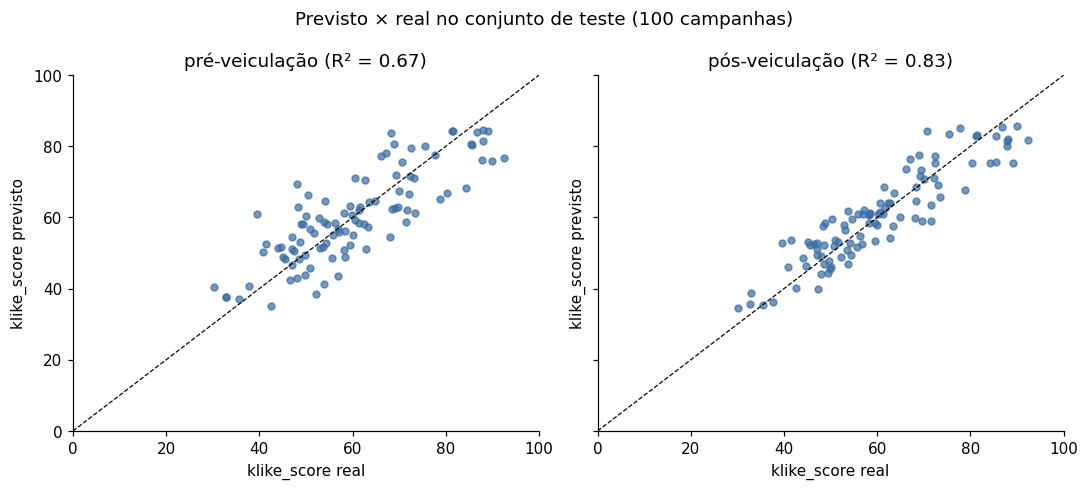

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, conjunto in zip(axes, CONJUNTOS):
    ax.scatter(y_test, previsoes[conjunto], color=COR, alpha=0.7, s=20)
    ax.plot([0, 100], [0, 100], color="black", linewidth=0.8, linestyle="--")
    ax.set(title=f"{conjunto} (R² = {r2_score(y_test, previsoes[conjunto]):.2f})",
           xlabel="klike_score real", ylabel="klike_score previsto", xlim=(0, 100), ylim=(0, 100))
fig.suptitle("Previsto × real no conjunto de teste (100 campanhas)")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "07_previsto_vs_real.png")

In [13]:
erros = pd.DataFrame({conjunto: (y_test - prev).abs() for conjunto, prev in previsoes.items() if conjunto in CONJUNTOS})
erros.groupby(X_test["platform"]).mean().assign(campanhas=X_test["platform"].value_counts()).round(2).rename_axis("MAE por plataforma")

,pré-veiculação,pós-veiculação,campanhas
MAE por plataforma,,,
LinkedIn,4.97,3.99,17
Meta,6.00,4.42,48
TikTok,8.17,6.06,35


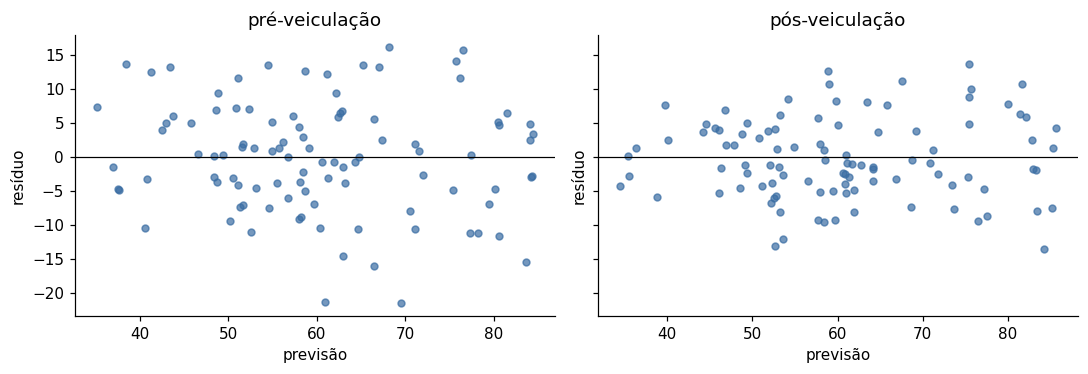

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, conjunto in zip(axes, CONJUNTOS):
    ax.scatter(previsoes[conjunto], y_test - previsoes[conjunto], color=COR, alpha=0.7, s=20)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(title=conjunto, xlabel="previsão", ylabel="resíduo")
fig.tight_layout()

- No teste, o modelo pré-veiculação erra em média 6,6 pontos (RMSE 8,2, R² 0,68) e o pós-veiculação 4,9 pontos (RMSE 6,0, R² 0,83), contra 11,7 do baseline. Os valores são próximos aos da validação cruzada: a escolha do modelo não inflou a estimativa.
- O pré-veiculação erra até 10 pontos em 74% das campanhas e o pós-veiculação em 92%, contra 48% do baseline. Os dois também põem as campanhas na ordem certa (Spearman 0,81 e 0,91). No treino, com previsões fora do fold, os números são praticamente os mesmos (75% e 89% com erro de até 10 pontos): o modelo não está sobreajustado.
- O modelo pré-veiculação comprime os extremos: subestima os scores muito altos e superestima os muito baixos. A parte que ele não explica depende de fatores que só aparecem depois da veiculação, como o CTR.
- O erro é maior no TikTok (MAE 8,2 no pré-veiculação) que no Meta (6,0) e no LinkedIn (5,0).
- Os resíduos não têm padrão em relação à previsão: a forma linear é adequada.

## 6. Importância das features

### 6.1 Coeficientes do modelo pré-veiculação

Como as binárias não são padronizadas, o coeficiente de cada uma é o efeito estimado de ter o atributo, em pontos de score, mantendo o resto fixo.

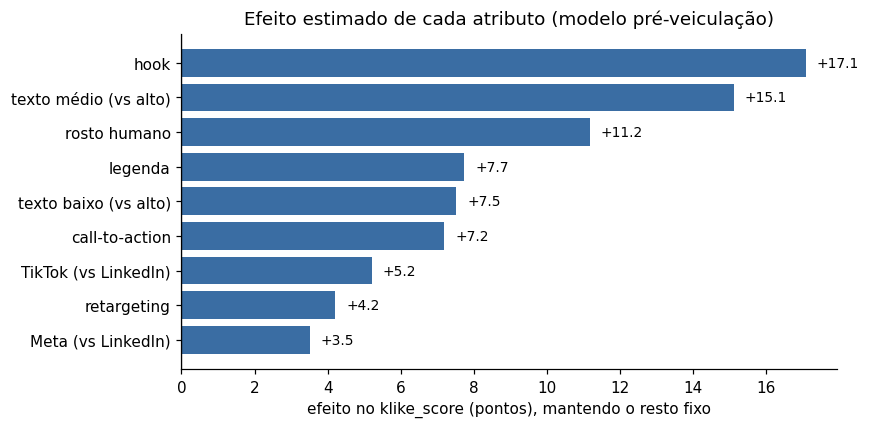

In [15]:
modelo_pre = finais["pré-veiculação"]
coeficientes = pd.Series(modelo_pre[-1].coef_, index=modelo_pre[1].get_feature_names_out())

efeitos = pd.Series({
    "hook": coeficientes["has_hook"],
    "rosto humano": coeficientes["has_face"],
    "legenda": coeficientes["has_subtitle"],
    "call-to-action": coeficientes["has_cta"],
    "texto médio (vs alto)": coeficientes["text_density_medium"] - coeficientes["text_density_high"],
    "texto baixo (vs alto)": coeficientes["text_density_low"] - coeficientes["text_density_high"],
    "retargeting": coeficientes["is_retargeting"],
    "TikTok (vs LinkedIn)": coeficientes["platform_TikTok"] - coeficientes["platform_LinkedIn"],
    "Meta (vs LinkedIn)": coeficientes["platform_Meta"] - coeficientes["platform_LinkedIn"],
}).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(efeitos.index, efeitos.values, color=COR)
for i, v in enumerate(efeitos.values):
    ax.text(v + 0.3, i, f"{v:+.1f}", va="center", fontsize=9)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="efeito no klike_score (pontos), mantendo o resto fixo",
       title="Efeito estimado de cada atributo (modelo pré-veiculação)")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "08_coeficientes.png")

In [16]:
# demais coeficientes (contexto e numéricas) para referência
coeficientes.drop(["has_hook", "has_face", "has_subtitle", "has_cta", "is_retargeting"]).sort_values().round(2).to_frame("coeficiente")

,coeficiente
text_density_high,-7.54
missingindicator_has_subtitle,-3.98
platform_LinkedIn,-2.91
category_Branding,-1.51
target_audience_age_18-24,-1.44
objective_engagement,-1.20
objective_app_install,-1.19
format_horizontal,-1.06
category_App Install,-0.95
music_voice_ratio,-0.69


- Os efeitos ajustados são muito próximos das diferenças brutas do passo 6 (hook +17,1 contra +17,6; rosto +11,2 contra +10,5), como esperado, já que os atributos do criativo são quase independentes entre si.
- Texto médio em vez de alto vale +15,1 pontos, e texto baixo em vez de alto +7,5: o efeito não segue a ordem dos níveis, o que confirma a codificação one-hot.
- O LinkedIn fica 3,5 a 5,2 pontos abaixo de Meta e TikTok, como no passo 7.
- Retargeting aparece com +4,2 depois do ajuste, embora a diferença bruta fosse quase zero. É uma decisão de mídia, e não do criativo, então não entra nas recomendações.
- Duração, música/voz, formato, categoria, objetivo e faixa etária têm coeficientes pequenos.

### 6.2 Importância por permutação no teste

Quanto o RMSE no teste piora quando os valores de uma feature são embaralhados. A permutação é feita nas features já limpas, que são as que o modelo recebe: embaralhar colunas brutas como `clicks` criaria campanhas impossíveis (a conta do CTR deixaria de fechar), e a limpeza passaria a "corrigi-las". Os níveis de uma categoria são embaralhados juntos.

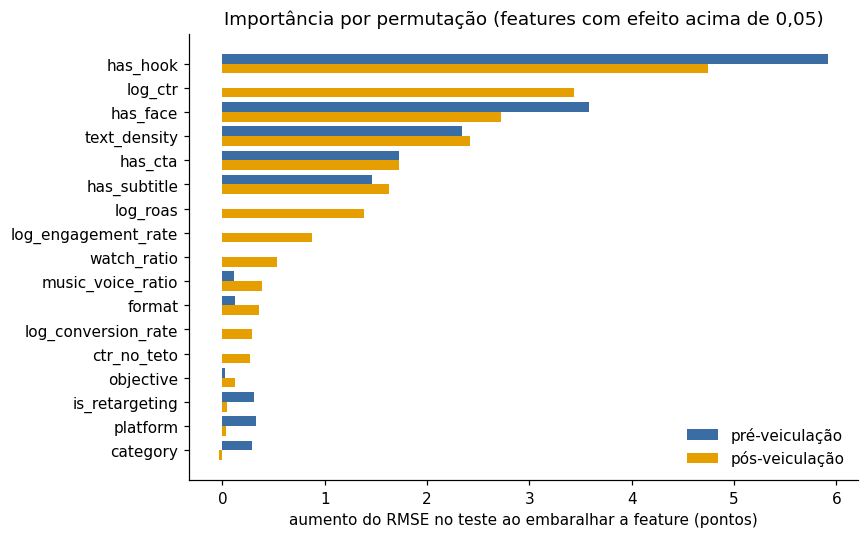

In [17]:
importancias = {}
for conjunto, modelo in finais.items():
    limpeza, resto = modelo[0], modelo[1:]
    usadas = [col for _, _, cols in resto[0].transformers_ if isinstance(cols, list) for col in cols]
    X_limpo = limpeza.transform(X_test)[usadas]
    r = permutation_importance(resto, X_limpo, y_test, scoring="neg_root_mean_squared_error",
                               n_repeats=30, random_state=42)
    importancias[conjunto] = pd.Series(r.importances_mean, index=usadas)
importancias = pd.DataFrame(importancias).fillna(0)
importancias = importancias[(importancias > 0.05).any(axis=1)].sort_values("pós-veiculação")

fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(importancias))
ax.barh(y + 0.2, importancias["pré-veiculação"], height=0.4, color=COR, label="pré-veiculação")
ax.barh(y - 0.2, importancias["pós-veiculação"], height=0.4, color="#E69F00", label="pós-veiculação")
ax.set_yticks(y, importancias.index)
ax.set(xlabel="aumento do RMSE no teste ao embaralhar a feature (pontos)",
       title="Importância por permutação (features com efeito acima de 0,05)")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "09_importancia_permutacao.png")

In [18]:
importancias.sort_values("pós-veiculação", ascending=False).round(2)

,pré-veiculação,pós-veiculação
has_hook,5.92,4.75
log_ctr,0.00,3.44
has_face,3.59,2.72
text_density,2.34,2.42
has_cta,1.73,1.72
has_subtitle,1.46,1.63
log_roas,0.00,1.39
log_engagement_rate,0.00,0.88
watch_ratio,0.00,0.54
music_voice_ratio,0.12,0.39


- Nos dois modelos, as features mais importantes são as do criativo: hook, rosto, densidade de texto, CTA e legenda.
- No pós-veiculação, o CTR (em log) é a segunda mais importante, seguido de ROAS e engajamento. A retenção perde importância porque boa parte dela já é explicada por hook e texto (passo 6).
- Plataforma, categoria, objetivo e retargeting quase não importam.

Do ponto de vista de negócio, faz sentido: o score mede a qualidade do criativo, e os atributos que mais pesam são os que prendem a atenção nos primeiros segundos, o que é coerente com o efeito deles no CTR e na retenção. As métricas entram como confirmação do desempenho real.

Uso no engine (Parte 3): o modelo pré-veiculação, porque responde "o que acontece com o score se eu mudar o criativo" sem depender de métricas que uma campanha nova ainda não tem. O pós-veiculação não serve para essa simulação: ao mudar o criativo, ele manteria o CTR fixo, quando na prática o CTR também mudaria.